# 07.3 — Risk Management

- Holding time to expiry, volatility, and interest rates fixed, a call cannot gain or lose more value per unit of underlying than the underlying's price change (in currency units, not percentage returns).
- Its response cannot have the opposite sign to the underlying's move: call value is non-decreasing in the underlying price.
- Therefore its delta is bounded by $0\leq\Delta=\frac{\partial C}{\partial S}\leq1$. Separately, the call's value itself cannot be negative: $C\geq0$.


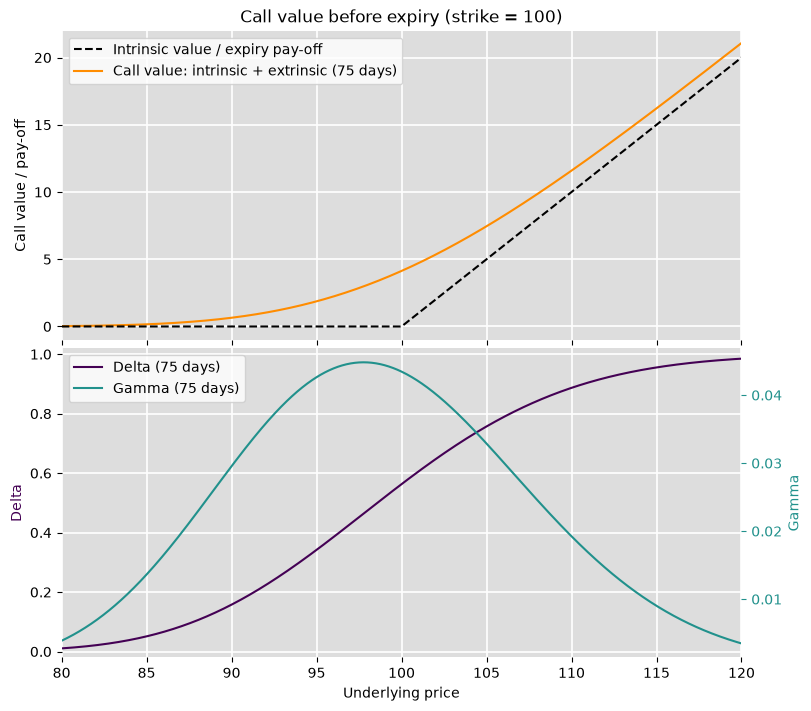

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

strike = 100
risk_free_rate = 0.05
volatility = 0.20
days_to_expiry = 75
tau = days_to_expiry / 365
underlying_price = np.linspace(80, 120, 801)
intrinsic_value = np.maximum(underlying_price - strike, 0)

# Black–Scholes: the discounted expected pay-off under risk-neutral GBM.
d1 = (
    np.log(underlying_price / strike) + (risk_free_rate + 0.5 * volatility**2) * tau
) / (volatility * np.sqrt(tau))
d2 = d1 - volatility * np.sqrt(tau)
call_value = underlying_price * norm.cdf(d1) - strike * np.exp(
    -risk_free_rate * tau
) * norm.cdf(d2)

delta = norm.cdf(d1)
gamma = norm.pdf(d1) / (underlying_price * volatility * np.sqrt(tau))

fig, (value_ax, greek_ax) = plt.subplots(
    2, 1, sharex=True, figsize=(8, 7), layout="constrained"
)
gamma_ax = greek_ax.twinx()
for ax in (value_ax, greek_ax):
    ax.set_facecolor("#dddddd")
    ax.set_axisbelow(True)
    ax.grid(color="white", linewidth=1.2)

value_ax.plot(
    underlying_price,
    intrinsic_value,
    color="black",
    linewidth=1.5,
    linestyle="--",
    zorder=3,
    label="Intrinsic value / expiry pay-off",
)
value_ax.plot(
    underlying_price,
    call_value,
    color="darkorange",
    linewidth=1.5,
    zorder=2,
    label=f"Call value: intrinsic + extrinsic ({days_to_expiry} days)",
)
value_ax.set(
    ylabel="Call value / pay-off",
    title="Call value before expiry (strike = 100)",
    xlim=(80, 120),
    ylim=(-1, 22),
)
value_ax.legend()

greek_ax.plot(
    underlying_price,
    delta,
    color="#440154",
    linewidth=1.5,
    label=f"Delta ({days_to_expiry} days)",
)
greek_ax.set(
    xlabel="Underlying price",
    ylabel="Delta",
    ylim=(-0.02, 1.02),
)
greek_ax.set_ylabel("Delta", color="#440154")

gamma_ax.plot(
    underlying_price,
    gamma,
    color="#21918c",
    linewidth=1.5,
    label=f"Gamma ({days_to_expiry} days)",
)
gamma_ax.set_ylabel("Gamma", color="#21918c")
gamma_ax.tick_params(axis="y", colors="#21918c")
delta_handles, delta_labels = greek_ax.get_legend_handles_labels()
gamma_handles, gamma_labels = gamma_ax.get_legend_handles_labels()
greek_ax.legend(
    delta_handles + gamma_handles, delta_labels + gamma_labels, loc="upper left"
)

for ax in (value_ax, greek_ax, gamma_ax):
    for spine in ax.spines.values():
        spine.set_visible(False)
plt.show()

## Gamma for calls and puts

Gamma is positive for both calls and puts. A put's delta increases from $-1$ to $0$ as the underlying price rises, so $\partial\Delta/\partial S>0$ just as it is for a call. Therefore, a trader who is long calls or long puts is always long gamma.

## Delta hedging

At an underlying price of $S_t=104.79$, this call has delta $\Delta=0.75$. Therefore, if long 4 calls, shorting 3 shares gives a delta-neutral position: $4(0.75)-3=0$.

An underlying position is affected almost exclusively by moves in the underlying market. Option prices are also affected by time to expiry, interest rates, volatility, and other factors, which can have a much greater impact under changing market conditions.


## Gamma Hedging

Delta is the instantaneous sensitivity of an option's price to changes in the underlying. As the underlying price changes, delta changes too. **Gamma**, the rate of change of delta with respect to the underlying, is therefore an important risk measure:

$$
\Delta = \frac{\partial V}{\partial S}, \qquad \Gamma = \frac{\partial \Delta}{\partial S} = \frac{\partial^2 V}{\partial S^2}.
$$

Long vanilla calls and puts both have **positive gamma**. Large gamma positions mean directional exposure (delta) can change rapidly as the underlying moves, making them difficult for new traders to manage. A delta-neutral position may therefore need frequent rebalancing.

Holding interest rates, implied volatility, time to expiry, and all other variables constant, the Taylor expansion of the option price for an underlying move $h$ is:

$$
V(S+h) = V(S) + \Delta h + \frac{1}{2}\Gamma h^2 + \cdots
$$

So, to second order, **the option's price change is approximately**:

$$
V(S+h)-V(S) \approx \Delta h + \frac{1}{2}\Gamma h^2.
$$

The delta term captures the current directional exposure; the gamma term captures how that exposure changes during the move.

If a trader wants to remain delta zero while seeking to capture an option's theoretical value, they must rebalance the delta hedge as the underlying moves; gamma hedging reduces the need for this rebalancing.